# Example of the aitlas toolbox in the context of change detection

## Import the required packages

In [ ]:
from aitlas.datasets import SZTAKIAirChangeDataset
from aitlas.utils import image_loader
from aitlas.models import UnetChangeDetection
from aitlas.transforms import MinMaxNormTranspose, ResizeToTensor, ResizePerChannelToTensor

## Visualize images and masks

In [ ]:
dataset_config = {
    "data_dir" : "./data/sztaki_airchange/",
}
dataset = SZTAKIAirChangeDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 13


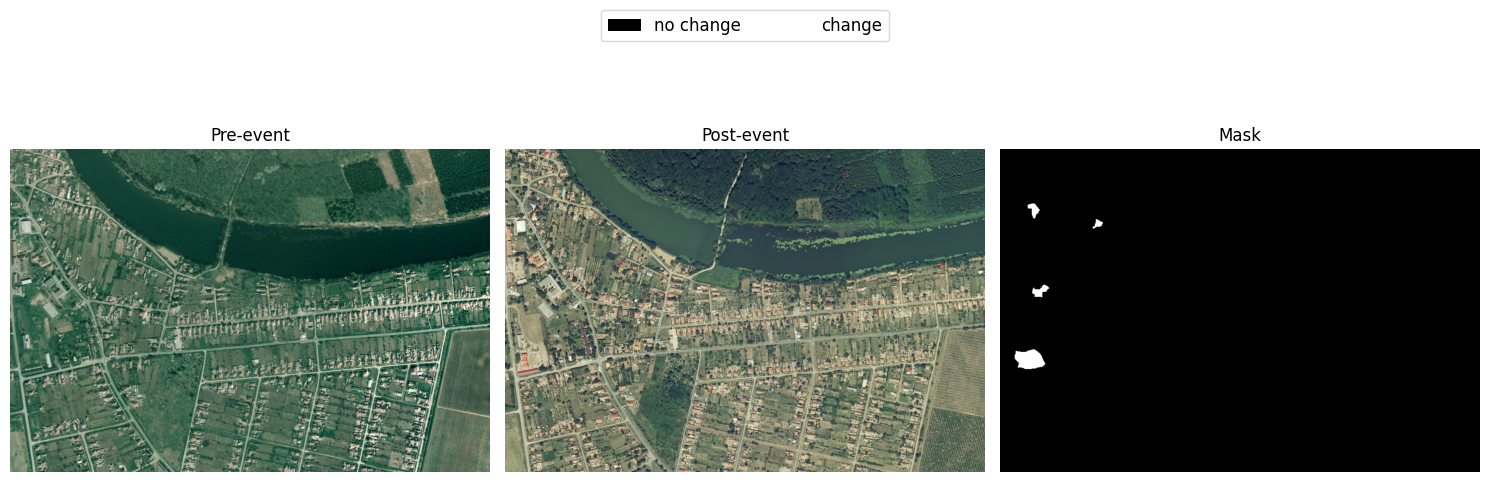

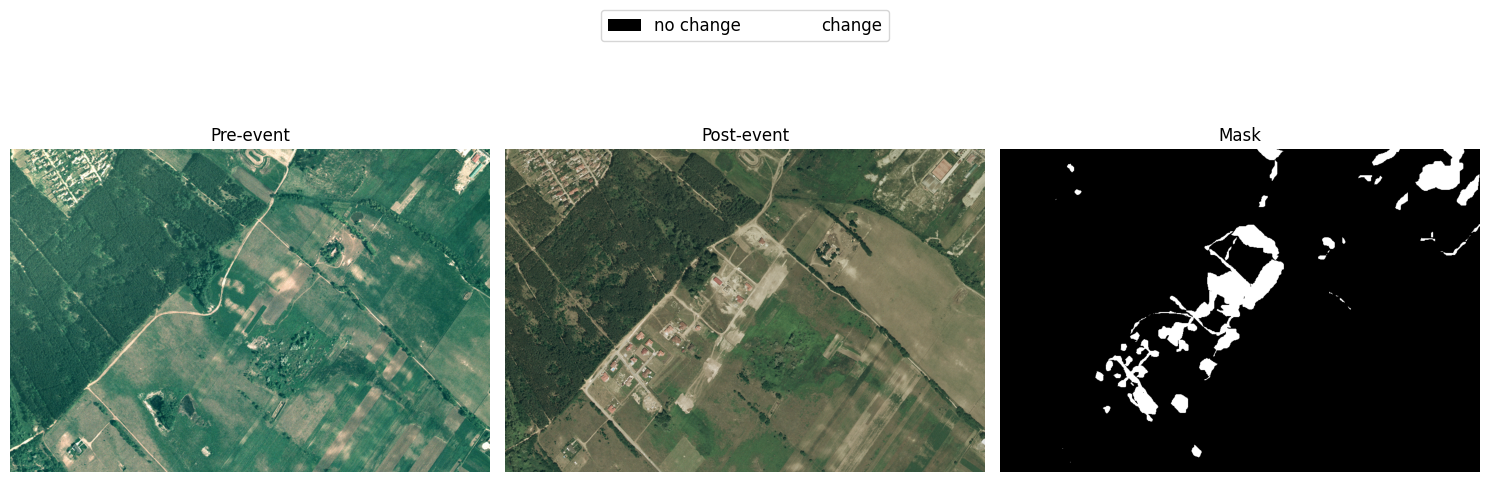

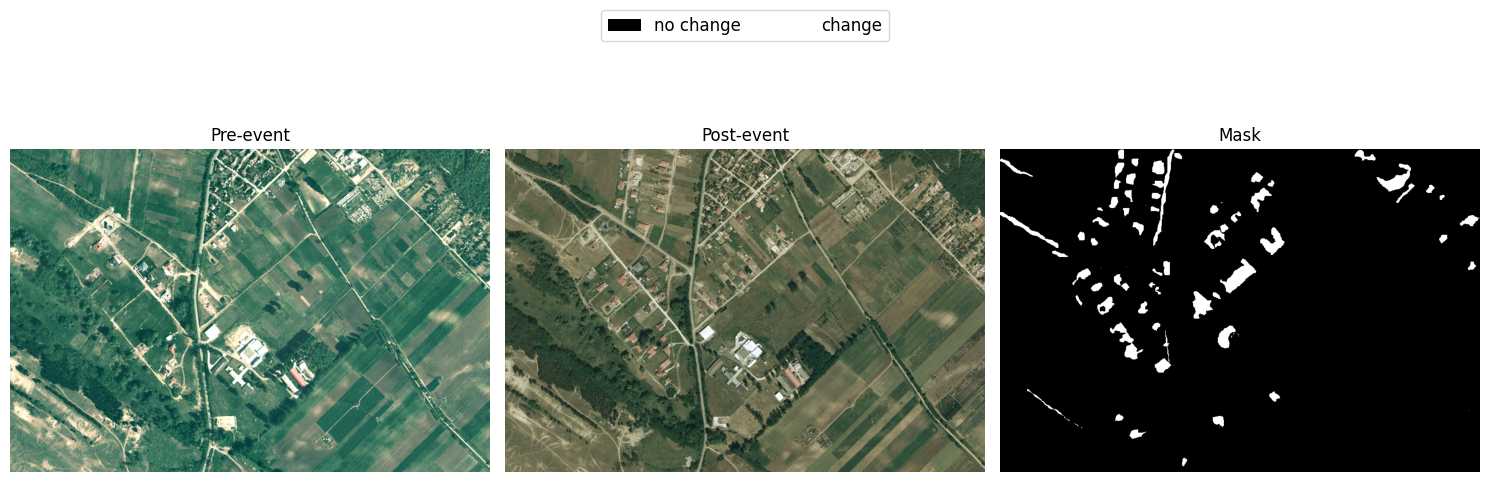

In [6]:
dataset.show_image(1);
dataset.show_image(10);
dataset.show_image(12);

In [34]:
dataset.data_distribution_table()

,Number of pixels
no change,1711412.0
change,116428.0


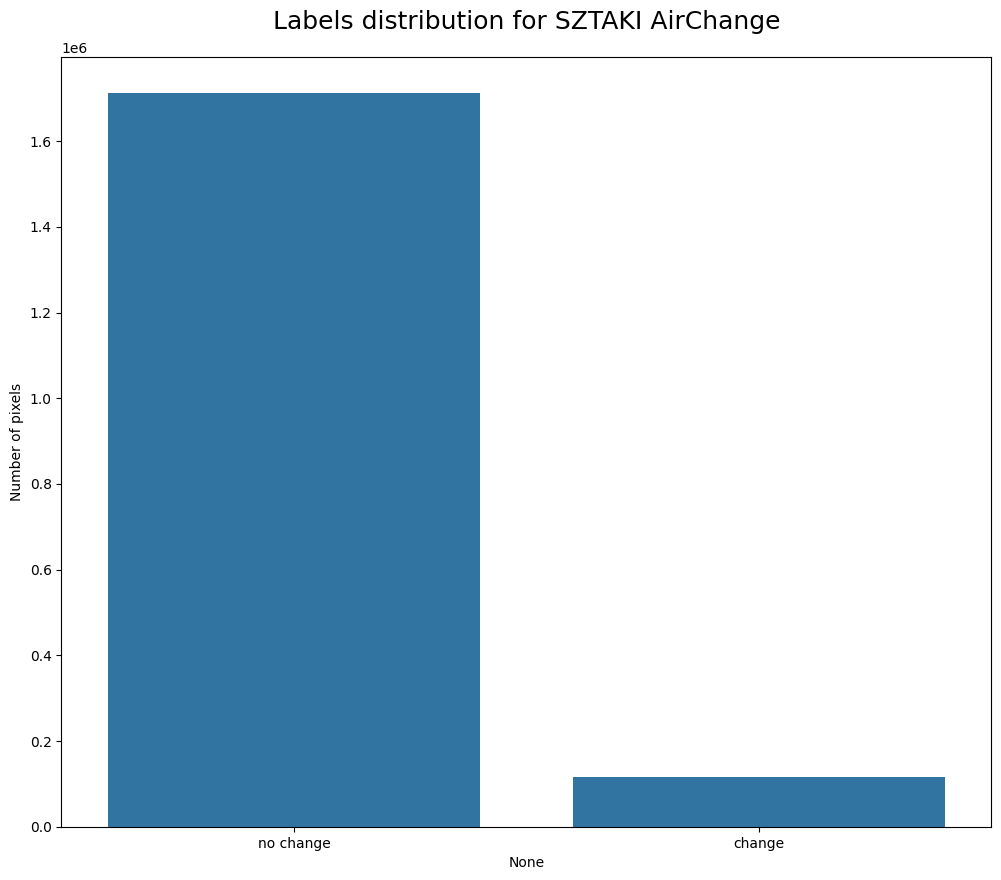

In [35]:
dataset.data_distribution_barchart();

## Load training and test data

In [ ]:
train_dataset_config = {
    "batch_size": 4,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "./data/sztaki_airchange/",
    "mode": "train",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
train_dataset = SZTAKIAirChangeDataset(train_dataset_config)

test_dataset_config = {
    "batch_size": 2,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "./data/sztaki_airchange/",
    "mode": "val",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
test_dataset = SZTAKIAirChangeDataset(test_dataset_config)
len(train_dataset), len(test_dataset)

(8, 2)

## Create the model

In [ ]:
epochs = 300
model_directory = "./data/experiments/sztaki_airchange"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": False, 
    "threshold": 0.5,
    "metrics": ["accuracy", "precision", "recall", "f1_score", "iou"]
}

model = UnetChangeDetection(model_config)
model.prepare()

## Start the training

In [9]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1',
)

model_path = model_directory + "/checkpoint.pth.tar"
model.load_model(model_path)
model.running_metrics.reset()
model.evaluate(dataset=test_dataset, model_path=model_path)
test_metrics = model.running_metrics.get_scores(model.metrics)

2026-01-26 09:23:05,918 INFO Starting training.
training: 100%|██████████| 2/2 [00:04<00:00,  2.39s/it]
2026-01-26 09:23:10,745 INFO epoch: 1, loss:  0.30068
testing on train set: 100%|██████████| 2/2 [00:04<00:00,  2.24s/it]
2026-01-26 09:23:16,664 INFO Accuracy:0.5221500396728516, Accuracy per Class:[0.08892059 0.95537949], Precision Micro:0.9473748773307163, Precision Macro:0.4736874386653582, Precision Weighted:0.9037776976372047, Precision per Class:[0.94737488 0.        ], Recall Micro:0.015192109466594276, Recall Macro:0.00796247953447899, Recall Weighted:0.015192109466594276, Recall per Class:[0.01592496 0.        ], F1_score Micro:0.029904667497889642, F1_score Macro:0.01566169283370578, F1_score Weighted:0.029881916924437292, F1_score per Class:[0.03132339 0.        ], IOU:0.015179299704197255, IOU mean:0.007955442107496843, IOU per Class:[0.01591088 0.        ]
training: 100%|██████████| 2/2 [00:04<00:00,  2.29s/it]
2026-01-26 09:23:21,247 INFO epoch: 2, loss:  0.29600
testi

## Predictions

2026-01-26 10:13:19,609 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/sztaki_airchange/checkpoint.pth.tar
2026-01-26 10:13:19,916 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/sztaki_airchange/checkpoint.pth.tar at epoch 301


2


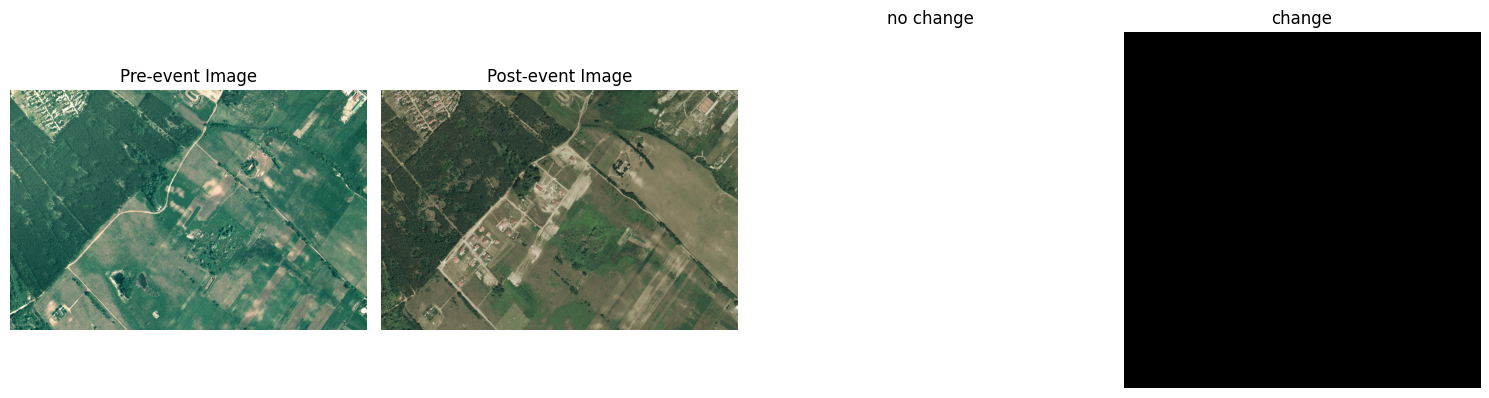

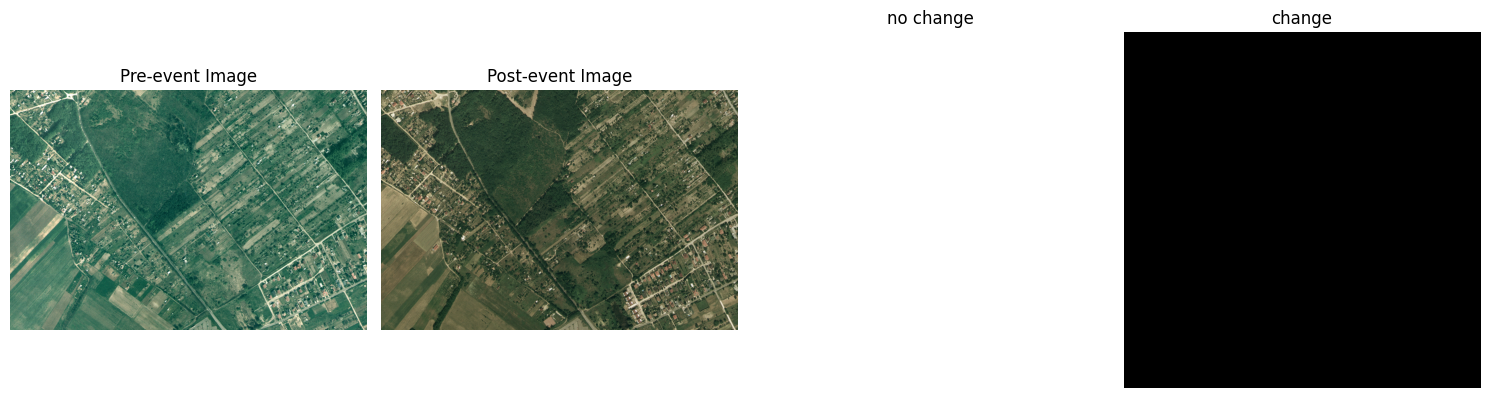

In [ ]:
model_path = "./data/experiments/sztaki_airchange/checkpoint.pth.tar"
labels = ["no change","change"]
transform = ResizeToTensor()
model.load_model(model_path)

test_dataset_config = {
    "data_dir" : "./data/sztaki_airchange/",
    "mode": "test"
}
test_dataset = SZTAKIAirChangeDataset(test_dataset_config)
print(len(test_dataset))

image1 = test_dataset[0][0][0]
image2 = test_dataset[0][0][1]
fig = model.predict_masks(image1, image2, labels, transform)

image1 = test_dataset[1][0][0]
image2 = test_dataset[1][0][1]
fig = model.predict_masks(image1, image2, labels, transform)